# Projekt 1 - model sentymentu dla recenzji Steam

Notatnik pokazuje: dane treningowe, kroki czyszczenia tekstu (z pułapkami z Prezentacji 2),
wybór stemming / lematyzacja, wyniki własnego modelu TF-IDF + regresja logistyczna
i porównanie z gotowym transformerem. Liczby czytam z plików w `results/`,
które tworzą `train_model.py`, `scripts/compare_transformer.py` i `scripts/evaluate_live.py`.

In [1]:
import json, os, sys
from pathlib import Path
os.chdir(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
sys.path.insert(0, ".")
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.max_colwidth", 120)

## 1. Dane treningowe

In [2]:
train = pd.read_csv("data/train.csv")
val = pd.read_csv("data/val.csv")
test = pd.read_csv("data/test.csv")
print("train / val / test:", len(train), len(val), len(test))
print("udział pozytywnych:", round(train.label.mean(), 3))
train.groupby("game").label.agg(["count", "mean"]).round(2).sort_values("count").head(10)

train / val / test: 12546 2688 2689
udział pozytywnych: 0.44


,count,mean
game,,
New World,336,0.67
Grand Theft Auto V,353,0.37
Counter-Strike 2,362,0.38
Dota 2,363,0.44
PUBG: Battlegrounds,374,0.36
Rust,390,0.43
Apex Legends,390,0.41
ARK: Survival Evolved,395,0.43
Rainbow Six Siege,396,0.43


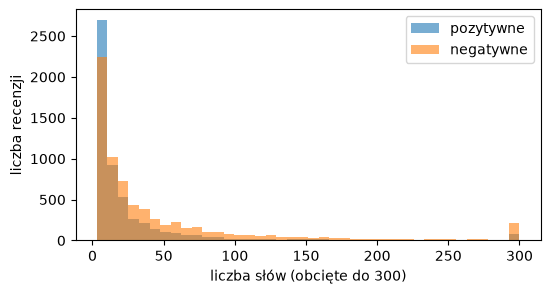

mediana słów - pozytywne: 11.0  negatywne: 20.0


In [3]:
words = train.text.str.split().str.len()
fig, ax = plt.subplots(figsize=(6, 3))
for lab, name in ((1, "pozytywne"), (0, "negatywne")):
    ax.hist(words[train.label == lab].clip(upper=300), bins=40, alpha=0.6, label=name)
ax.set_xlabel("liczba słów (obcięte do 300)"); ax.set_ylabel("liczba recenzji"); ax.legend()
plt.show()
print("mediana słów - pozytywne:", words[train.label == 1].median(), " negatywne:", words[train.label == 0].median())

## 2. Czyszczenie tekstu krok po kroku

Przykłady odpowiadają pułapkom z zajęć: negacja usuwana jako stopword, HTML/BBCode,
liczby (ocena 2/10), wykrzykniki i emoji jako nośnik emocji.

In [4]:
from text_cleaning import explain_steps
examples = [
    "This is not a good game.",
    "[b]Don't buy it[/b], 2/10. More at https://example.com",
    "I LOVE this game!!! \U0001F60D",
]
for ex in examples:
    display(pd.DataFrame(explain_steps(ex, normalize="stem"), columns=["krok", "wynik"]))

,krok,wynik
0,Tekst oryginalny,This is not a good game.
1,"HTML/BBCode/URL usunięte, negacje rozwinięte, małe litery",this is not a good game.
2,Tokeny,"this, is, not, a, good, game"
3,Bez stopwords (negacje zostają),"not, good, game"
4,Stemming (Porter),"not, good, game"


,krok,wynik
0,Tekst oryginalny,"[b]Don't buy it[/b], 2/10. More at https://example.com"
1,"HTML/BBCode/URL usunięte, negacje rozwinięte, małe litery","do not buy it , 2/10. more at"
2,Tokeny,"do, not, buy, it, 2/10, more, at"
3,Bez stopwords (negacje zostają),"not, buy, 2/10"
4,Stemming (Porter),"not, buy, 2/10"


,krok,wynik
0,Tekst oryginalny,I LOVE this game!!! 😍
1,"HTML/BBCode/URL usunięte, negacje rozwinięte, małe litery",i love this game!!! 😍
2,Tokeny,"i, love, this, game, !, 😍"
3,Bez stopwords (negacje zostają),"love, game, !, 😍"
4,Stemming (Porter),"love, game, !, 😍"


### Stemming a lematyzacja (zadanie 1 z Prezentacji 2)

In [5]:
from text_cleaning import clean_text
s = "The developers were fixing the crashes, but the studies of better games are running"
pd.DataFrame({
    "bez normalizacji": [clean_text(s, normalize=None)],
    "stemming (Porter)": [clean_text(s, normalize="stem")],
    "lematyzacja (spaCy)": [clean_text(s, normalize="lemma")],
}).T

,0
bez normalizacji,developers fixing crashes studies better games running
stemming (Porter),develop fix crash studi better game run
lematyzacja (spaCy),developer fix crash study game run


### Który wariant wybrać? Porównanie na zbiorze walidacyjnym

Ten sam model (TF-IDF 1-2-gramy + LogReg, C=1), zmieniam tylko preprocessing.
Ostatni wiersz to błąd z pułapki 1: pełna lista stopwords razem z negacjami.

In [6]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, accuracy_score
import text_cleaning as tc
from train_model import make_vectorizer

def check(name, normalize, stopwords=True):
    t0 = time.time()
    xtr = tc.clean_many(train.text.tolist(), normalize, stopwords)
    xva = tc.clean_many(val.text.tolist(), normalize, stopwords)
    t = time.time() - t0
    m = Pipeline([("tfidf", make_vectorizer()), ("clf", LogisticRegression(max_iter=2000))])
    m.fit(xtr, train.label)
    p = m.predict(xva)
    return {"wariant": name, "F1 val": round(f1_score(val.label, p), 4),
            "accuracy val": round(accuracy_score(val.label, p), 4), "czas czyszczenia [s]": round(t, 1)}

rows = [check("bez normalizacji", None), check("stemming", "stem"),
        check("lematyzacja", "lemma"), check("stemming, bez usuwania stopwords", "stem", False)]
saved = tc.STOPWORDS
tc.STOPWORDS = saved | tc.NEGATIONS      # celowo zła lista: usuwa też not/no/never
rows.append(check("stemming, stopwords RAZEM z negacjami", "stem"))
tc.STOPWORDS = saved
norm_table = pd.DataFrame(rows)
norm_table

,wariant,F1 val,accuracy val,czas czyszczenia [s]
0,bez normalizacji,0.7802,0.8196,0.6
1,stemming,0.7839,0.8181,3.2
2,lematyzacja,0.7746,0.8099,18.2
3,"stemming, bez usuwania stopwords",0.7826,0.8192,4.6
4,"stemming, stopwords RAZEM z negacjami",0.7770,0.8151,3.1


Różnice między normalizacjami są małe (recenzje gier to krótkie, potoczne teksty,
a bigramy i tak łapią dużo kontekstu). Wybrałem **stemming**: najlepsze F1 na walidacji
i kilka razy szybszy od lematyzacji spaCy, co ma znaczenie w GUI. Usunięcie negacji
pogarsza wynik - zgodnie z pułapką z zajęć.

## 3. Własny model: TF-IDF + regresja logistyczna (zbiór testowy)

In [7]:
m = json.load(open("results/metrics.json"))
print("najlepsze C:", m["best_C"], " F1 w CV:", m["cv_f1_by_C"])
models = ["tfidf_logreg", "tfidf_linear_svc", "tfidf_naive_bayes"]
pd.DataFrame({k: m[k] for k in models}).T[["accuracy", "precision", "recall", "f1"]]

najlepsze C: 3  F1 w CV: {'0.1': 0.6626, '0.3': 0.7434, '1.0': 0.7814, '3.0': 0.7906, '10.0': 0.7818}


,accuracy,precision,recall,f1
tfidf_logreg,0.8185,0.8113,0.766,0.788
tfidf_linear_svc,0.8077,0.7897,0.7677,0.7786
tfidf_naive_bayes,0.788,0.8896,0.5921,0.711


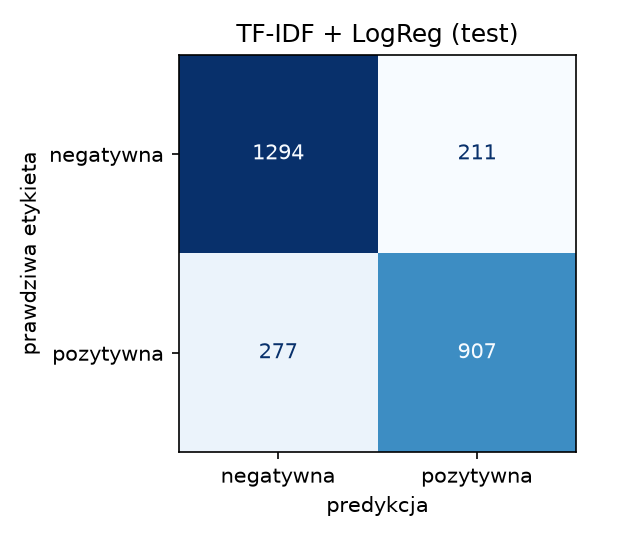

ROC AUC: 0.9034


In [8]:
display(Image("results/confusion_matrix.png", width=380))
print("ROC AUC:", m["tfidf_logreg"]["roc_auc"])

### Czego nauczył się model (największe wagi)

In [9]:
pd.read_csv("results/top_features.csv").head(15)

,negatywne,waga_neg,pozytywne,waga_poz
0,not,-6.40,best,7.52
1,not recommend,-5.80,10/10,6.22
2,worst,-5.61,amaz,6.15
3,no,-5.55,fun,5.64
4,crash,-5.52,great,5.55
5,updat,-5.31,good,5.49
6,unplay,-5.21,love,5.35
7,bore,-5.16,not bad,4.54
8,ban,-4.65,peak,4.31
9,cheater,-4.47,awesom,3.80


## 4. Porównanie z transformerem

`distilbert-base-uncased-finetuned-sst-2-english` - gotowy model dostrojony na zdaniach
z recenzji filmów (SST-2). Liczony na tym samym zbiorze testowym, bez dotrenowania.

rozmiar testu: 2689  urządzenie transformera: cpu


,accuracy,precision,recall,f1,ms_per_text
TF-IDF + LogReg,0.8185,0.8113,0.766,0.788,0.22
DistilBERT SST-2,0.8066,0.8451,0.6867,0.7577,92.24


zgodność predykcji obu modeli: 0.7917


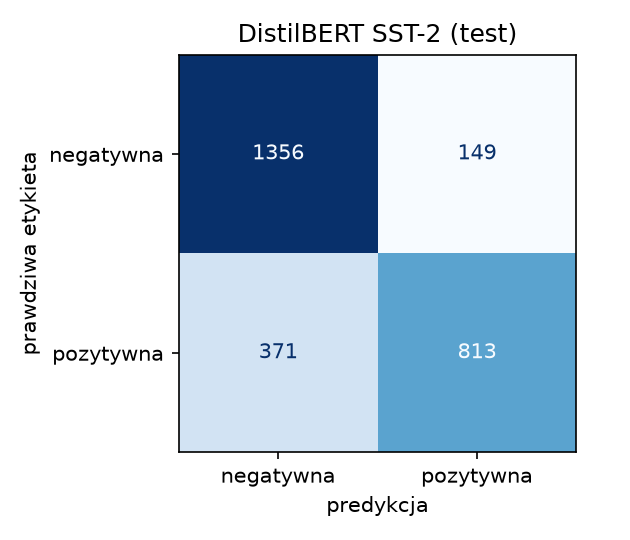

In [10]:
tc_res = json.load(open("results/transformer_comparison.json"))
print("rozmiar testu:", tc_res["n_test"], " urządzenie transformera:", tc_res["device_transformer"])
cols = ["accuracy", "precision", "recall", "f1", "ms_per_text"]
display(pd.DataFrame({"TF-IDF + LogReg": tc_res["tfidf_logreg"],
                      "DistilBERT SST-2": tc_res["distilbert_sst2"]}).T[cols])
print("zgodność predykcji obu modeli:", tc_res["agreement"])
display(Image("results/confusion_matrix_transformer.png", width=380))

## 5. Analiza błędów własnego modelu

In [11]:
from sentiment import OwnModel
own = OwnModel()
labels, conf = own.predict(test.text.tolist())
test["pred"], test["pewnosc"] = labels, conf.round(2)
fp = test[(test.pred == 1) & (test.label == 0)].sort_values("pewnosc", ascending=False)
fn = test[(test.pred == 0) & (test.label == 1)].sort_values("pewnosc", ascending=False)
print("Model mówi POZYTYWNA, autor nie poleca:")
display(fp[["text", "pewnosc"]].head(5))
print("Model mówi NEGATYWNA, autor poleca:")
display(fn[["text", "pewnosc"]].head(5))

Model mówi POZYTYWNA, autor nie poleca:


,text,pewnosc
590,best game ever bradar,1.00
253,Greatest game I've ever played.,0.96
1008,All mods disapired !!!,0.94
275,Good if you enjoy COD,0.93
1938,this game is very fun and enjoyable although sometimes bad random are a thing this game is fun when you have good te...,0.92


Model mówi NEGATYWNA, autor poleca:


,text,pewnosc
1374,EA = money beggar,0.98
405,Don't act dumb.,0.96
1213,I did NOT find the arK.\n0/10 woudld buy again,0.96
974,THIS GAME FUCKING SUCKS,0.96
1026,it doesn't suit me ， to me it's like a piece of shit,0.95


Typowe źródła błędów: sarkazm i memy ("10/10 would crash again"), recenzje,
które chwalą grę, ale krytykują wydawcę, oraz bardzo krótkie teksty.

## 6. Dane z Internetu: gry spoza zbioru treningowego

In [12]:
live = pd.read_csv("results/live_eval.csv")
print("data pobrania:", live.data_pobrania.iloc[0])
live.pivot(index="gra", columns="model", values="f1").round(3)

data pobrania: 2026-11-16


model,own,transformer
gra,,
Baldur's Gate 3,0.880,0.829
HELLDIVERS 2,0.828,0.820
Hades,0.866,0.852
Hollow Knight,0.843,0.817
Lethal Company,0.822,0.807
Monster Hunter Wilds,0.804,0.794
Palworld,0.827,0.811
Path of Exile 2,0.807,0.813
Portal 2,0.800,0.819


## 7. Wnioski

In [13]:
own_f1 = tc_res["tfidf_logreg"]["f1"]; tr_f1 = tc_res["distilbert_sst2"]["f1"]
speed = tc_res["distilbert_sst2"]["ms_per_text"] / tc_res["tfidf_logreg"]["ms_per_text"]
print(f"F1 na teście: własny {own_f1:.3f}, DistilBERT {tr_f1:.3f}")
print(f"Transformer jest ok. {speed:.0f}x wolniejszy na tym samym sprzęcie")
r = live[live.gra == "RAZEM"].set_index("model").f1
print(f"F1 na świeżych recenzjach z Internetu: własny {r['own']:.3f}, DistilBERT {r['transformer']:.3f}")

F1 na teście: własny 0.788, DistilBERT 0.758
Transformer jest ok. 419x wolniejszy na tym samym sprzęcie
F1 na świeżych recenzjach z Internetu: własny 0.831, DistilBERT 0.818
